# This notebook applies the linear method of regressing out the impact of ENSO from TOA anomalies at each latitude

Cleaned up from de_enso_toa_with_sst in cleaned_model_sebm. This code was made with assistance from Claude

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
import scipy.io as io
from scipy.stats import linregress
from scipy.signal import butter, filtfilt



from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

In [2]:
temp_sst=xr.open_dataset('/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/regridded_temp_40members_CESM1.nc')
temp_sst=temp_sst.__xarray_dataarray_variable__

toa_flux=xr.open_dataset('/glade/derecho/scratch/aurorabf/EBM/moist/test_variance_scaling/regridded_flux_40members_CESM1.nc')
toa_flux=toa_flux.__xarray_dataarray_variable__

In [3]:
temp_sst_anom=temp_sst-temp_sst.mean('ensemble_member')
toa_flux_anom=toa_flux-toa_flux.mean('ensemble_member')

In [4]:
#https://github.com/ramp-kits/el_nino/blob/master/el_nino_starting_kit.ipynb and https://ncar.github.io/PySpark4Climate/tutorials/Oceanic-Ni%C3%B1o-Index/

#"NOAA's operational definitions of El Niño and La Niña conditions are based upon the Oceanic Niño Index [ONI]. The ONI is defined as the 3-month running means of SST anomalies in the Niño 3.4 region [5N-5S, 120-170W]." (from the second link)
#Define region for el nino index (3.4)
en_lat_bottom = -5
en_lat_top = 5
en_lon_left = -170
en_lon_right = -120

def get_area_mean(tas, lat_bottom, lat_top, lon_left, lon_right):
    # Compute area-weighted mean temperatures in a region
    region = tas.loc[:, lat_bottom:lat_top, lon_left:lon_right]
    
    weights = np.cos(np.deg2rad(region.lat))
    weighted_tas = region.weighted(weights)
    
    return weighted_tas.mean(dim=('lat', 'lon'))

def get_enso_mean(tas):
    # Compute mean temperature in the Nino 3.4 region
    return get_area_mean(tas, en_lat_bottom, en_lat_top, en_lon_left, en_lon_right)

def bandpass_filter_enso(data, low_year=7, high_year=2, fs=12):
    #Applies a Butterworth bandpass filter. Needs longer period (low_year), shorter period (high_year) and sampling frequency (fs)

    enso=get_enso_mean(data)
    # Convert years to frequency (1/T)
    lowcut = 1 / (low_year)
    highcut = 1 / (high_year)
    
    b, a = butter(4, [lowcut, highcut], btype='band',fs=12)
    
    # Apply the filter
    filtered_values = filtfilt(b, a, enso)
    enso_filtered = enso.copy(data=filtered_values)
    return enso_filtered


def stack_bandpassfilterenso(n, temp_sst_anom):
    # Bandpassed ENSO index for the first n members, stacked over (ensemble_member, time)
    sst = temp_sst_anom.isel(ensemble_member=slice(0, n))
    combined = xr.concat(
        [bandpass_filter_enso(sst.isel(ensemble_member=i)) for i in range(n)],
        dim=sst.ensemble_member,  # keep the real member labels
    )
    return combined.stack(stacked_time=('ensemble_member', 'time'))

def stack_temp(n,temp,n0=1):
    combined=temp.sel(ensemble_member=slice(n0, n)).stack(stacked_time=('ensemble_member', 'time')) #stack together time and ensemble dimensions
    return combined

def linregress_ensemble_enso(n,temp_sat_anom,temp_sst_anom,lat):
    result = linregress(stack_bandpassfilterenso(n, temp_sst_anom), stack_temp(n,temp_sat_anom).sel(lat=lat)) #linearly regress bandpassed oni index vs temperature anomalies
    return result.intercept, result.slope

def de_enso(temp_sat_anom,temp_sst_anom,lat,n): 
    #n is the number of ensemble members to fit the statistical model with. but ultimately you detrend each
    intercept,slope=linregress_ensemble_enso(n,temp_sat_anom.mean('lon'),temp_sst_anom,lat) #apply linear regression
    all=[]
    for i in range(40):
        detrend=temp_sat_anom[i,:,:,:].mean('lon').sel(lat=lat)-slope*bandpass_filter_enso(temp_sst_anom[i,:,:,:]) #remove the slope*oni
        all.append(detrend)
    return xr.concat(all, dim='ensemble_member')


def de_enso_vectorized(temp_sat_anom, temp_sst_anom, lat, n):
    # Remove ENSO from SAT at every latitude in lat, fitting the slope on the first n members
    sat = temp_sat_anom.sel(lat=lat).mean('lon')

    # Fit on the first n members, pooled over members and time
    x = stack_bandpassfilterenso(n, temp_sst_anom)
    y = stack_temp(n, sat)
    slope = xr.cov(x, y, dim='stacked_time') / x.var('stacked_time', ddof=1)

    # Remove from every member
    n_all = temp_sst_anom.sizes['ensemble_member']
    enso = stack_bandpassfilterenso(n_all, temp_sst_anom).unstack('stacked_time')
    return sat - slope * enso

In [5]:
a_lin=de_enso_vectorized(toa_flux_anom,temp_sst_anom,temp_sst_anom.lat,20)

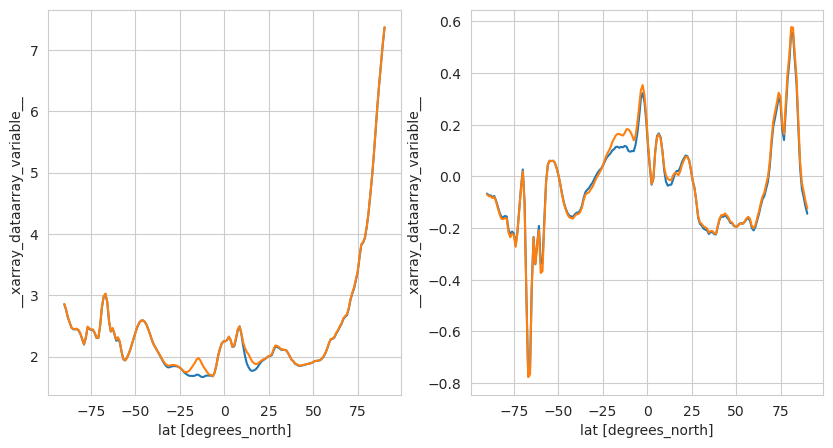

In [6]:
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(10,5))
a_lin.std('ensemble_member')[80*12-1:(80+25)*12-1,:].mean('time').plot(ax=ax1)
toa_flux_anom.mean('lon').std('ensemble_member')[80*12-1:(80+25)*12-1,:].mean('time').plot(ax=ax1)


(a_lin.std('ensemble_member')[-30*12:,:].mean('time')-a_lin.std('ensemble_member')[80*12-1:(80+25)*12-1,:].mean('time')).plot(ax=ax2)
(toa_flux_anom.mean('lon').std('ensemble_member')[-30*12:,:].mean('time')-toa_flux_anom.mean('lon').std('ensemble_member')[80*12-1:(80+25)*12-1,:].mean('time')).plot(ax=ax2)

In [7]:
cwd = %pwd
path = cwd + "/data/toa_detrend_linear_regression_enso_norollingmean_sst_oct2026.nc"

a_lin.to_netcdf(path)